# Integración de datos: captaciones wifi + tiempo en el aeropuerto

**Objetivo:** construir un dataset integrado y coherente que relacione la actividad wifi del aeropuerto con las condiciones meteorológicas, para poder responder a preguntas de negocio de la aerolínea.

**Fuentes que se integran**

| Fuente | Dónde está | Granularidad original |
|---|---|---|
| Captaciones wifi de junio 2026 (ya limpias) | InfluxDB, bucket `captaciones_historico` | una fila por captación |
| Tiempo histórico en Madrid-Barajas | API de archivo de Open-Meteo | una fila por hora |

**Clave de unión:** la hora (UTC), porque es la granularidad común a las dos fuentes.

**Resultado:** una tabla con una fila por hora (720 horas), que se guarda en el bucket `dataset_integrado` y en `dataset_integrado.csv`.

**Preguntas de negocio que guían el trabajo**
1. ¿En qué franjas horarias hay más pasajeros conectados (cuándo mostrar los anuncios)?
2. ¿Cambia el perfil del pasajero (idioma, sistema operativo, edad) según la franja?
3. ¿Influye el tiempo (lluvia, temperatura) en la actividad? ¿Tiene sentido lanzar campañas de paraguas?

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

import warnings
from influxdb_client.client.warnings import MissingPivotFunction
warnings.simplefilter("ignore", MissingPivotFunction)

INFLUX_URL = os.environ.get("INFLUX_URL", "http://localhost:8086")
INFLUX_TOKEN = os.environ.get("INFLUX_TOKEN", "ulGO8tFBeUJx3XPcOYCZza25T0jvh2qDP5pOjX5Zl7npRjcWorBpDgHafUdvSLFC7bgdeSYbfvkAt9q89VHD7Q==")      # token pandas-integracion
INFLUX_ORG = os.environ.get("INFLUX_ORG", "AeroAdd")
BUCKET_ORIGEN = "captaciones_julio"
BUCKET_DESTINO = "dataset_integrado"

LAT, LON = 40.4936, -3.5668          # Madrid-Barajas
ZONA = "Europe/Madrid"
SUBIR = True                         # True para escribir en InfluxDB

## 1. Adquisición de las dos fuentes

### 1.1 Captaciones desde InfluxDB (Flux → pandas)
Se consulta el campo `edad` de cada captación junto con sus tags. `group()` junta todas las series en una sola tabla.

In [2]:
def leer_captaciones():
    from influxdb_client import InfluxDBClient
    q = f'''
    from(bucket: "{BUCKET_ORIGEN}")
      |> range(start: 2026-05-31T00:00:00Z, stop: 2026-07-01T00:00:00Z)
      |> filter(fn: (r) => r._measurement == "captaciones" and r._field == "edad")
      |> group()
      |> keep(columns: ["_time", "_value", "fabricante", "os", "idioma", "pais", "rango_edad"])
    '''
    with InfluxDBClient(url=INFLUX_URL, token=INFLUX_TOKEN, org=INFLUX_ORG, timeout=300_000) as client:
        res = client.query_api().query_data_frame(q)
    if isinstance(res, list):
        res = pd.concat(res, ignore_index=True)
    res = res[["_time", "_value", "fabricante", "os", "idioma", "pais", "rango_edad"]]
    res = res.rename(columns={"_time": "hora", "_value": "edad"})
    res["hora"] = pd.to_datetime(res["hora"], utc=True)
    return res


capt = leer_captaciones()
print(f"Captaciones leídas de InfluxDB: {len(capt):,}")
capt.head()

Captaciones leídas de InfluxDB: 461,843


,hora,edad,fabricante,os,idioma,pais,rango_edad
0,2026-06-15 17:23:49+00:00,38,ASUS,Android,ca-ES,AT,35-44
1,2026-06-14 17:26:57+00:00,70,ASUS,Android,ca-ES,AT,65-85
2,2026-06-21 07:03:43+00:00,70,ASUS,Android,ca-ES,AT,65-85
3,2026-06-21 17:47:40+00:00,68,ASUS,Android,ca-ES,AT,65-85
4,2026-06-21 18:28:40+00:00,68,ASUS,Android,ca-ES,AT,65-85


### 1.2 Tiempo histórico desde la API de Open-Meteo
Se pide en GMT (= UTC) para que coincida con los timestamps de InfluxDB. Se empieza el 31 de mayo porque la primera captación (00:00 hora de Madrid del 1 de junio) es del 31 de mayo a las 22:00 UTC.

In [3]:
def leer_tiempo():
    import requests
    r = requests.get(
        "https://archive-api.open-meteo.com/v1/archive",
        params={"latitude": LAT, "longitude": LON,
                "start_date": "2026-05-31", "end_date": "2026-06-30",
                "hourly": "temperature_2m,precipitation,wind_speed_10m,cloud_cover",
                "timezone": "GMT"},
        timeout=60)
    r.raise_for_status()
    t = pd.DataFrame(r.json()["hourly"])
    t["hora"] = pd.to_datetime(t["time"], utc=True)
    return t.drop(columns="time").rename(columns={
        "temperature_2m": "temperatura", "precipitation": "precipitacion",
        "wind_speed_10m": "viento", "cloud_cover": "nubosidad"})


tiempo = leer_tiempo()
print(f"Horas de tiempo leídas: {len(tiempo)}")
tiempo.head()

Horas de tiempo leídas: 744


,temperatura,precipitacion,viento,nubosidad,hora
0,22.2,0.0,3.9,4,2026-05-31 00:00:00+00:00
1,21.3,0.0,9.6,9,2026-05-31 01:00:00+00:00
2,20.0,0.0,6.5,8,2026-05-31 02:00:00+00:00
3,19.2,0.0,7.4,12,2026-05-31 03:00:00+00:00
4,18.6,0.0,9.2,1,2026-05-31 04:00:00+00:00


## 2. Integración
Las captaciones se agregan **por hora** (calculando también el perfil del pasajero en cada hora) y se unen con el tiempo por la clave `hora`. Después se añaden variables derivadas útiles para el negocio: franja horaria, fin de semana y si llovió.

In [4]:
def integrar(capt, tiempo):
    c = capt.copy()
    c["hora"] = c["hora"].dt.floor("h")
    c["es_ios"] = (c["os"] == "iOS")
    c["es_apple"] = (c["fabricante"] == "Apple")
    c["es_espana"] = (c["pais"] == "ES")
    c["habla_ingles"] = c["idioma"].str.startswith("en")

    g = c.groupby("hora")
    base = pd.DataFrame({"captaciones": g.size(), "edad_media": g["edad"].mean()})
    for col, nombre in [("es_ios", "pct_ios"), ("es_apple", "pct_apple"),
                        ("es_espana", "pct_espana"), ("habla_ingles", "pct_ingles")]:
        base[nombre] = g[col].mean() * 100

    # Calendario completo de horas: las horas sin captaciones cuentan como 0
    horas = pd.date_range(c["hora"].min(), c["hora"].max(), freq="h")      # solo el periodo con captaciones
    base = base.reindex(horas)
    base["captaciones"] = base["captaciones"].fillna(0)
    base = base.fillna(0)          # perfil sin datos = 0 (solo ocurre si no hay captaciones)
    base.index.name = "hora"

    df = base.join(tiempo.set_index("hora"), how="left")

    local = df.index.tz_convert(ZONA)
    df["hora_local"] = local.hour
    df["dia_semana"] = local.dayofweek
    df["fin_de_semana"] = pd.Series(local.dayofweek >= 5, index=df.index).map({True: "si", False: "no"})
    df["llueve"] = (df["precipitacion"] > 0).map({True: "si", False: "no"})
    df["franja"] = pd.cut(df["hora_local"], bins=[-1, 6, 9, 17, 19, 23],
                          labels=["noche", "punta_manana", "dia", "punta_tarde", "noche_tarde"]).astype(str)
    df["franja"] = df["franja"].replace({"noche_tarde": "noche"})
    return df


df = integrar(capt, tiempo)
print(f"Dataset integrado: {df.shape[0]} filas x {df.shape[1]} columnas")
df.head()

Dataset integrado: 720 filas x 15 columnas


,captaciones,edad_media,pct_ios,pct_apple,pct_espana,pct_ingles,temperatura,precipitacion,viento,nubosidad,hora_local,dia_semana,fin_de_semana,llueve,franja
hora,,,,,,,,,,,,,,,
2026-05-31 22:00:00+00:00,47,50.361702,25.531915,23.404255,21.276596,36.170213,25.6,0.0,2.1,20,0,0,no,no,noche
2026-05-31 23:00:00+00:00,70,49.585714,20.000000,11.428571,28.571429,31.428571,24.6,0.0,16.2,44,1,0,no,no,noche
2026-06-01 00:00:00+00:00,79,45.443038,27.848101,24.050633,25.316456,27.848101,23.3,0.0,14.1,44,2,0,no,no,noche
2026-06-01 01:00:00+00:00,88,48.272727,25.000000,11.363636,38.636364,25.000000,22.2,0.0,14.1,39,3,0,no,no,noche
2026-06-01 02:00:00+00:00,69,51.014493,36.231884,15.942029,37.681159,26.086957,20.9,0.0,13.2,83,4,0,no,no,noche


### 2.1 Comprobaciones de coherencia
Antes de usar el dataset se comprueba que no se ha perdido ni inventado nada en la unión.

In [5]:
comprobaciones = {
    "Se conservan todas las captaciones": int(df["captaciones"].sum()) == len(capt),
    "Una fila por hora, sin huecos": df.index.is_unique and (df.index.to_series().diff().dropna() == pd.Timedelta("1h")).all(),
    "Sin nulos en el tiempo": not df[["temperatura", "precipitacion", "viento", "nubosidad"]].isna().any().any(),
    "Porcentajes entre 0 y 100": df.filter(like="pct_").stack().between(0, 100).all(),
}
for nombre, ok in comprobaciones.items():
    print(("OK   " if ok else "FALLA"), nombre)
print("\nHoras sin ninguna captación:", int((df["captaciones"] == 0).sum()))
assert all(comprobaciones.values()), "Hay comprobaciones que fallan"

OK    Se conservan todas las captaciones
OK    Una fila por hora, sin huecos
OK    Sin nulos en el tiempo
OK    Porcentajes entre 0 y 100

Horas sin ninguna captación: 0


## 3. Análisis: relaciones entre las fuentes y preguntas de negocio

### Pregunta 1 y 2: ¿cuándo hay más pasajeros y cómo cambia su perfil?

,horas,captaciones_por_hora,edad_media,pct_ios,pct_espana,pct_ingles
franja,,,,,,
punta_tarde,60,2216.2,50.1,35.0,27.9,27.1
punta_manana,90,1762.7,50.0,34.9,28.0,27.0
noche,330,316.0,49.9,35.4,27.8,26.5
dia,240,274.7,50.0,34.8,28.5,26.8


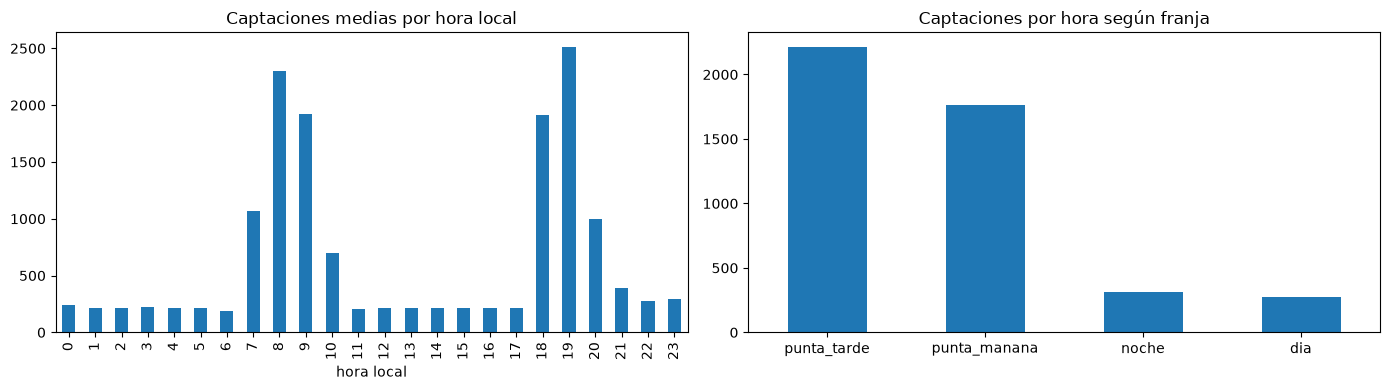

In [6]:
por_franja = df.groupby("franja").agg(
    horas=("captaciones", "size"),
    captaciones_por_hora=("captaciones", "mean"),
    edad_media=("edad_media", "mean"),
    pct_ios=("pct_ios", "mean"),
    pct_espana=("pct_espana", "mean"),
    pct_ingles=("pct_ingles", "mean"),
).round(1).sort_values("captaciones_por_hora", ascending=False)
display(por_franja)

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df.groupby("hora_local")["captaciones"].mean().plot.bar(ax=ax[0], title="Captaciones medias por hora local")
por_franja["captaciones_por_hora"].plot.bar(ax=ax[1], title="Captaciones por hora según franja", rot=0)
ax[0].set_xlabel("hora local"); ax[1].set_xlabel("")
plt.tight_layout(); plt.show()

### Pregunta 3: ¿influye el tiempo en la actividad?
Se miden las correlaciones entre captaciones, perfil y variables meteorológicas, y se compara la actividad con y sin lluvia.

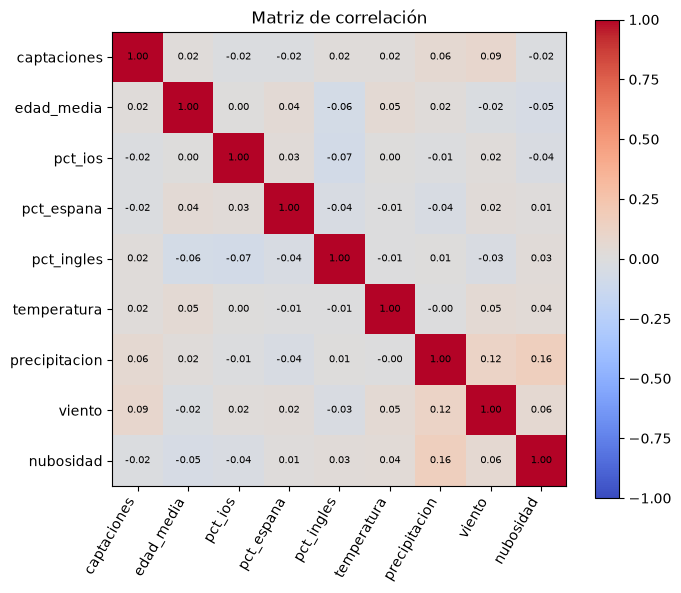

        horas  captaciones_por_hora
llueve                             
no        700                 637.7
si         20                 772.0


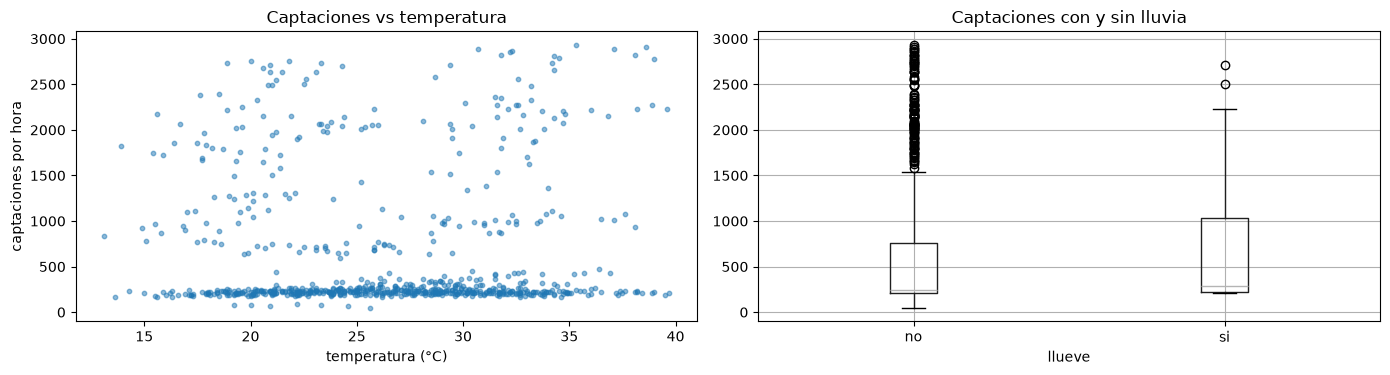

In [7]:
vars_corr = ["captaciones", "edad_media", "pct_ios", "pct_espana", "pct_ingles",
             "temperatura", "precipitacion", "viento", "nubosidad"]
corr = df[vars_corr].corr()

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(vars_corr))); ax.set_xticklabels(vars_corr, rotation=60, ha="right")
ax.set_yticks(range(len(vars_corr))); ax.set_yticklabels(vars_corr)
for i in range(len(vars_corr)):
    for j in range(len(vars_corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im); ax.set_title("Matriz de correlación"); plt.tight_layout(); plt.show()

print(df.groupby("llueve")["captaciones"].agg(["count", "mean"]).round(1).rename(
    columns={"count": "horas", "mean": "captaciones_por_hora"}))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].scatter(df["temperatura"], df["captaciones"], s=10, alpha=0.5)
ax[0].set_xlabel("temperatura (°C)"); ax[0].set_ylabel("captaciones por hora"); ax[0].set_title("Captaciones vs temperatura")
df.boxplot(column="captaciones", by="llueve", ax=ax[1]); ax[1].set_title("Captaciones con y sin lluvia"); plt.suptitle("")
plt.tight_layout(); plt.show()

In [8]:
def fuerza(r):
    r = abs(r)
    return "inapreciable" if r < 0.1 else "débil" if r < 0.3 else "moderada" if r < 0.5 else "fuerte"

r_ll = df["captaciones"].corr(df["precipitacion"])
r_t = df["captaciones"].corr(df["temperatura"])
mejor = por_franja.index[0]
print(f"- La franja con más actividad es '{mejor}' ({por_franja.iloc[0]['captaciones_por_hora']:.0f} captaciones/hora de media).")
print(f"- Correlación captaciones-precipitación: {r_ll:.2f} ({fuerza(r_ll)}).")
print(f"- Correlación captaciones-temperatura:  {r_t:.2f} ({fuerza(r_t)}).")

- La franja con más actividad es 'punta_tarde' (2216 captaciones/hora de media).
- Correlación captaciones-precipitación: 0.06 (inapreciable).
- Correlación captaciones-temperatura:  0.02 (inapreciable).


### Conclusiones para el cliente

- **Cuándo anunciar:** las franjas de mayor actividad son las que concentran más pasajeros conectados; ahí rinde más cada anuncio.
- **A quién anunciar:** el perfil (idioma, sistema operativo, edad, país) por franja indica en qué idioma y con qué tono conviene mostrar cada campaña.
- **Papel del tiempo:** si la correlación entre tiempo y actividad es inapreciable, el tiempo no sirve para predecir *cuántos* pasajeros habrá, pero sigue siendo útil como disparador de campañas (por ejemplo, anunciar paraguas cuando llueve o es probable que llueva). Esto es lo que hacen los flujos de Node-RED en tiempo real.

## 4. Almacenamiento del dataset integrado
Se guarda en CSV (para la memoria) y, si SUBIR = True, en el bucket dataset_integrado de InfluxDB con una fila por hora. Los tags (franja, fin_de_semana, llueve) permiten filtrar rápido en Grafana; el resto de columnas numéricas son fields (como decimales, para evitar conflictos de tipo).

In [9]:
df.to_csv("dataset_integrado.csv", encoding="utf-8-sig")
print("Guardado dataset_integrado.csv")

TAGS = ["franja", "fin_de_semana", "llueve"]
FIELDS = ["captaciones", "edad_media", "pct_ios", "pct_apple", "pct_espana", "pct_ingles",
          "temperatura", "precipitacion", "viento", "nubosidad", "hora_local", "dia_semana"]


def subir(df):
    from influxdb_client import InfluxDBClient, WriteOptions
    if not INFLUX_TOKEN:
        raise RuntimeError("Falta INFLUX_TOKEN")
    out = df[TAGS + FIELDS].copy()
    out[FIELDS] = out[FIELDS].astype(float)
    with InfluxDBClient(url=INFLUX_URL, token=INFLUX_TOKEN, org=INFLUX_ORG) as client:
        w = client.write_api(write_options=WriteOptions(batch_size=500, flush_interval=2_000))
        w.write(bucket=BUCKET_DESTINO, record=out,
                data_frame_measurement_name="horario_integrado",
                data_frame_tag_columns=TAGS)
        w.close()


if SUBIR:
    subir(df)
    print(f"Subidas {len(df)} filas a {BUCKET_DESTINO}")
else:
    print("Subida desactivada (SUBIR = False)")

Guardado dataset_integrado.csv
Subidas 720 filas a dataset_integrado


## 5. Verificación en InfluxDB
```flux
from(bucket: "dataset_integrado")
  |> range(start: 2026-05-31T00:00:00Z, stop: 2026-07-01T00:00:00Z)
  |> filter(fn: (r) => r._measurement == "horario_integrado" and r._field == "captaciones")
  |> group()
  |> sum()
```
Debe devolver **461.843**, el mismo número de captaciones que el histórico.